<a href="https://colab.research.google.com/github/lejan392/Case_study_Unsupervised_lejan/blob/main/case_study_unsupervised_learning_lejan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv('/content/drive/MyDrive/DSA B13/Dataset/adult_dataset.csv')
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [3]:
df.shape

(48842, 15)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [5]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [6]:
df.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [7]:
df.replace('?', np.nan, inplace=True)

In [8]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

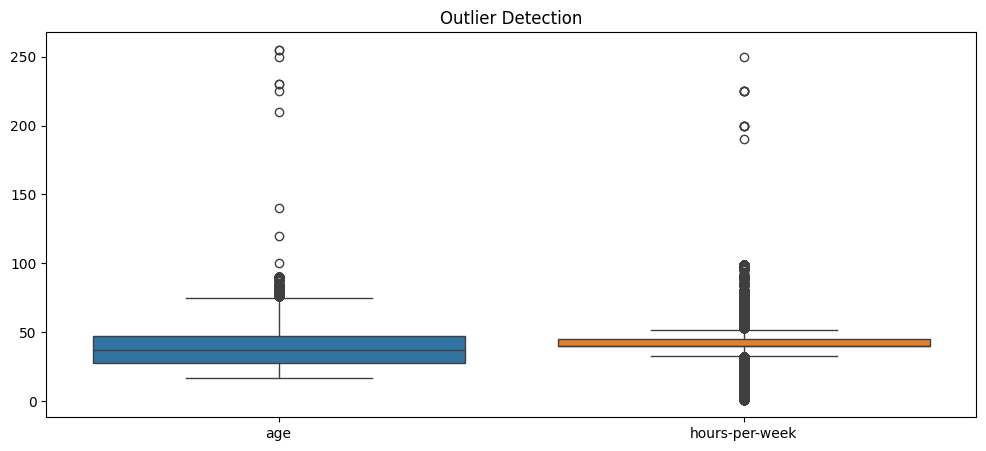

In [9]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df[['age', 'hours-per-week']])
plt.title('Outlier Detection')
plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [11]:
for col in ['age', 'hours-per-week']:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [12]:
X = df.drop(columns=['income', 'fnlwgt', 'education'])

X.head()

,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39.0,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States
1,50.0,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States
2,38.0,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States
3,53.0,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States
4,28.0,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba


In [13]:
cat_cols = X.select_dtypes(include='object').columns
X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X.head()

,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,13,2174,0,40.0,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,50.0,13,0,0,32.5,False,False,False,False,True,...,False,False,False,False,False,False,False,True,False,False
2,38.0,9,0,0,40.0,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
3,53.0,7,0,0,40.0,False,False,True,False,False,...,False,False,False,False,False,False,False,True,False,False
4,28.0,13,0,0,40.0,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False


In [14]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

(48842, 81)


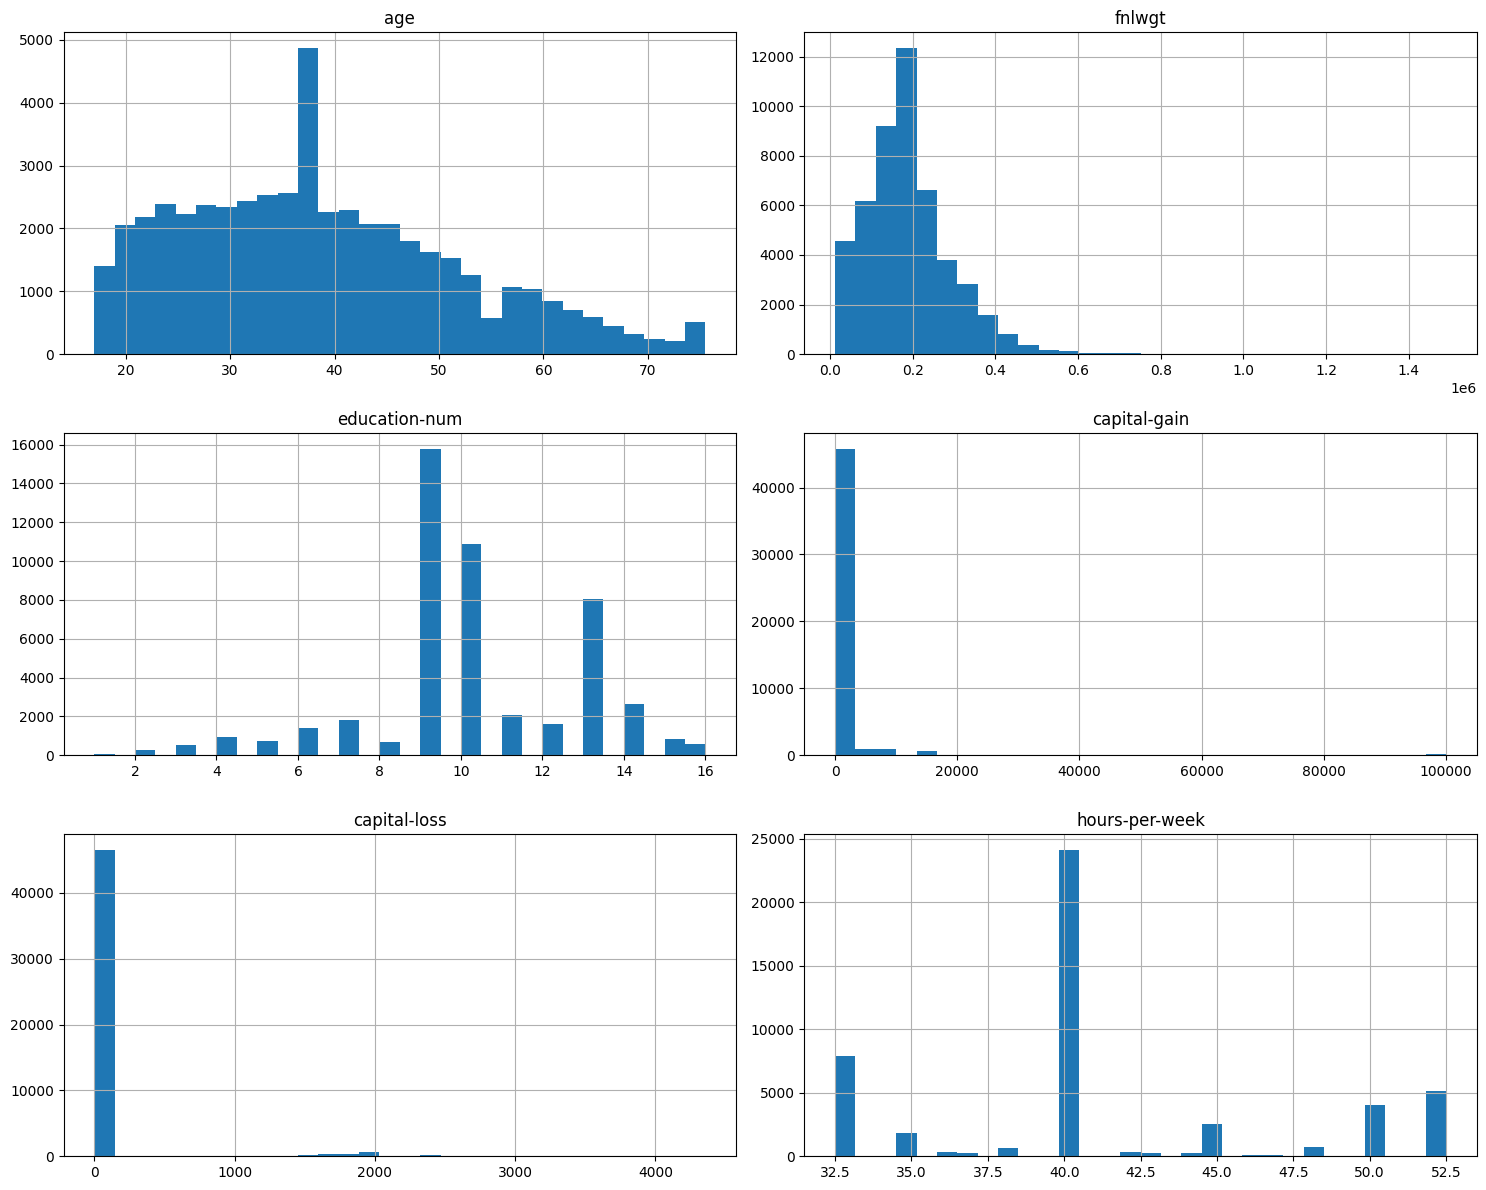

In [15]:
df.hist(figsize=(15, 12), bins=30)
plt.tight_layout()
plt.show()

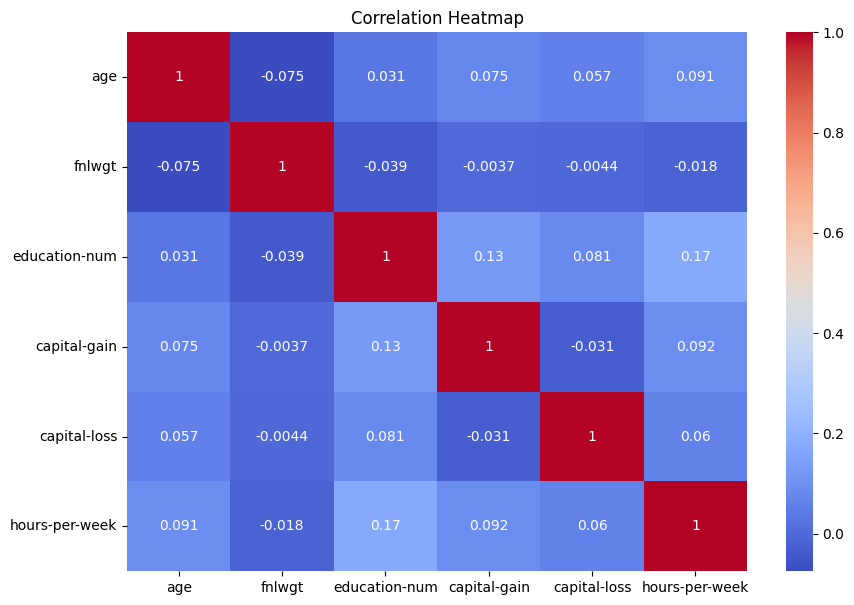

In [16]:
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlation Heatmap')
plt.show()

In [17]:
from sklearn.decomposition import PCA

In [18]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(X_pca.shape)

(48842, 2)


In [19]:
print(pca.explained_variance_ratio_)
print("Total variance:",sum(pca.explained_variance_ratio_))

[0.03995538 0.03049734]
Total variance: 0.07045272155591477


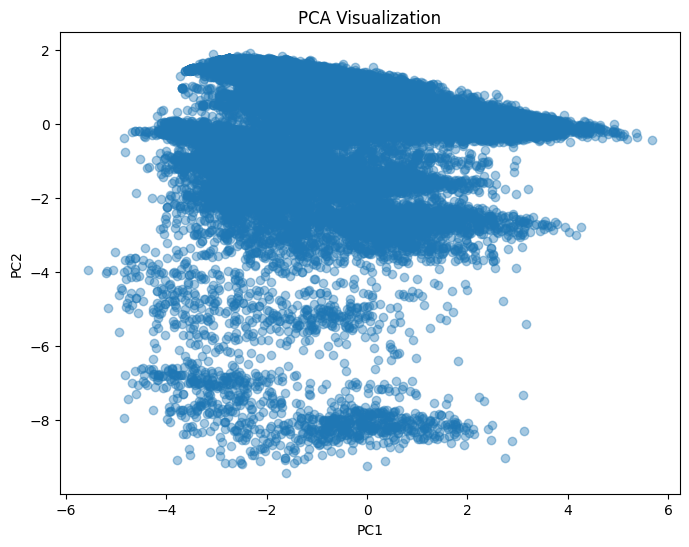

In [20]:
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.4
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA Visualization')
plt.show()

In [21]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [22]:
inertia = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

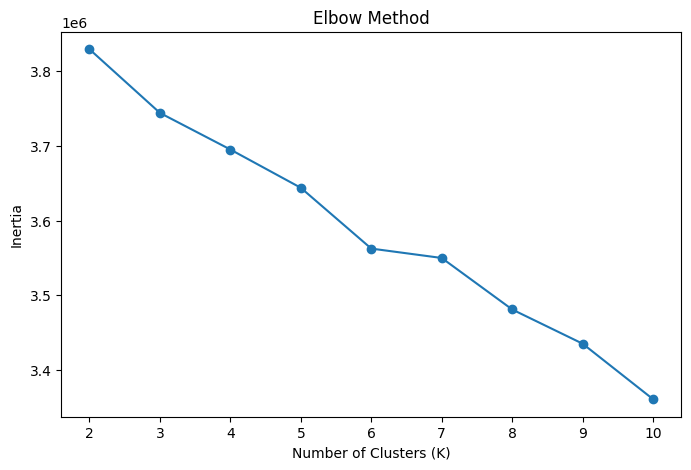

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [24]:
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled,labels,sample_size=5000,random_state=42)
    print(k, score)

2 0.06880595302060818
3 0.04523423113163931
4 0.04911191010725439
5 0.04881436076265578
6 0.055702582563458065
7 0.06651058063273224
8 0.07025445094456875
9 0.07453156203069411
10 0.05311980691893189


In [25]:
kmeans = KMeans(n_clusters=3,random_state=42,n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

In [26]:
df['KMeans_Cluster'].value_counts()

,count
KMeans_Cluster,
2,21399
0,20744
1,6699


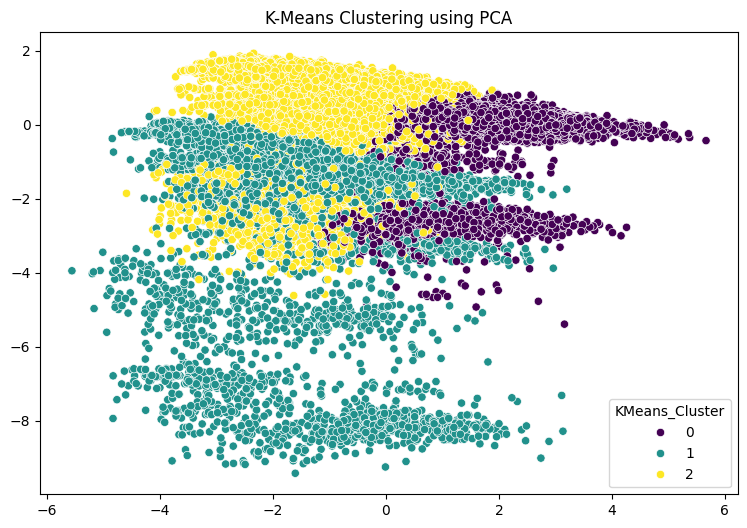

In [27]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0],y=X_pca[:, 1],hue=df['KMeans_Cluster'],palette='viridis')
plt.title('K-Means Clustering using PCA')
plt.show()

In [28]:
from sklearn.cluster import AgglomerativeClustering

sample_indices = df.sample(n=5000,random_state=42).index
X_sample = X_scaled[df.index.get_indexer(sample_indices)]

agg = AgglomerativeClustering(n_clusters=3,linkage='ward')
agg_labels = agg.fit_predict(X_sample)
print(pd.Series(agg_labels).value_counts())

2    4606
0     389
1       5
Name: count, dtype: int64


In [29]:
print(silhouette_score(X_sample, agg_labels))

0.547655900138616


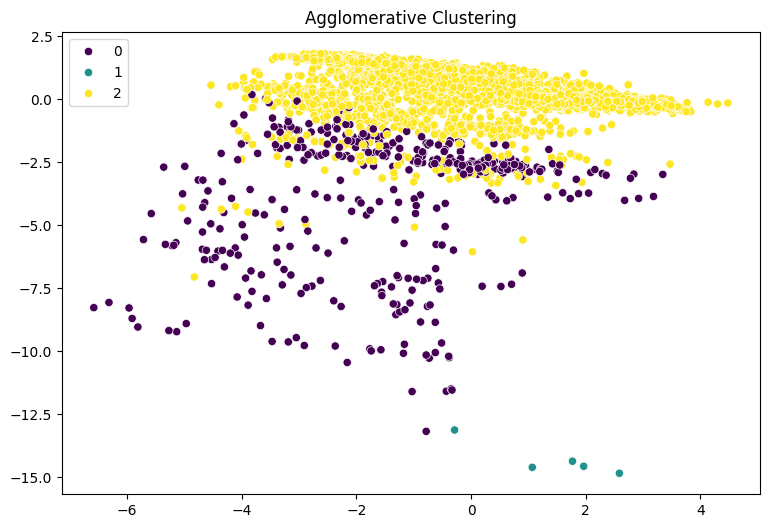

In [30]:
X_sample_pca = PCA(n_components=2).fit_transform(X_sample)
plt.figure(figsize=(9, 6))

sns.scatterplot(x=X_sample_pca[:, 0],y=X_sample_pca[:, 1],hue=agg_labels,palette='viridis')
plt.title('Agglomerative Clustering')
plt.show()

In [31]:
cluster_profile = df.groupby('KMeans_Cluster')[
    ['age', 'education-num', 'capital-gain',
     'capital-loss', 'hours-per-week']].mean()
print(cluster_profile)

                      age  education-num  capital-gain  capital-loss  \
KMeans_Cluster                                                         
0               43.303027      10.344244   1897.846172    124.126494   
1               37.573742       9.788327    812.458128     68.785789   
2               34.205594       9.910790    368.813636     57.858405   

                hours-per-week  
KMeans_Cluster                  
0                    42.915711  
1                    40.012614  
2                    39.748026  


In [32]:
print(df.groupby('KMeans_Cluster')['occupation'].agg(lambda x: x.mode()[0]))

KMeans_Cluster
0    Prof-specialty
1    Prof-specialty
2    Prof-specialty
Name: occupation, dtype: object


In [33]:
print(df.groupby('KMeans_Cluster')['education'].agg(lambda x: x.mode()[0]))

KMeans_Cluster
0    HS-grad
1    HS-grad
2    HS-grad
Name: education, dtype: object


In [34]:
pd.crosstab(df['KMeans_Cluster'],df['income'],normalize='index') * 100

income,<=50K,<=50K.,>50K,>50K.
KMeans_Cluster,,,,
0,36.747975,18.212495,30.187042,14.852487
1,56.784595,27.854904,10.329900,5.030602
2,62.119725,31.735128,4.145054,2.000093
